***EX 10***

Dataset Shape: (56, 9)

Columns:
Index(['customer_id', 'age', 'gender', 'annual_income', 'credit_score',
       'employed', 'marital_status', 'no_of_children', 'responded'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 56 entries, 0 to 55
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     55 non-null     float64
 1   age             34 non-null     float64
 2   gender          56 non-null     object 
 3   annual_income   34 non-null     float64
 4   credit_score    54 non-null     float64
 5   employed        56 non-null     object 
 6   marital_status  55 non-null     object 
 7   no_of_children  55 non-null     float64
 8   responded       56 non-null     object 
dtypes: float64(5), object(4)
memory usage: 4.1+ KB

Missing Values:
customer_id        1
age               22
gender             0
annual_income     22
credit_score       2
employed   

,customer_id,age,annual_income,credit_score,no_of_children
count,55.000000,34.000000,34.000000,54.000000,55.000000
mean,28.309091,36.977941,82485.294118,725.000000,1.309091
std,16.464184,11.735786,52612.143617,80.628428,1.168613
min,1.000000,26.000000,40000.000000,610.000000,0.000000
25%,14.500000,30.250000,50500.000000,680.000000,0.000000
50%,27.000000,34.500000,81000.000000,720.000000,1.000000
75%,41.500000,41.000000,93750.000000,767.500000,2.000000
max,56.000000,93.250000,287500.000000,1130.000000,3.000000



Campaign Response:
responded
No     29
Yes    27
Name: count, dtype: int64


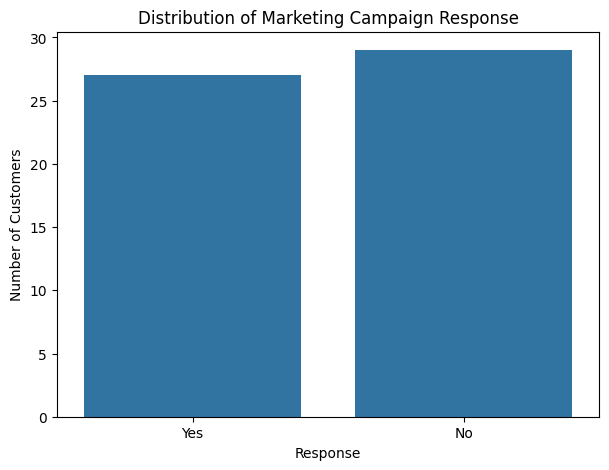

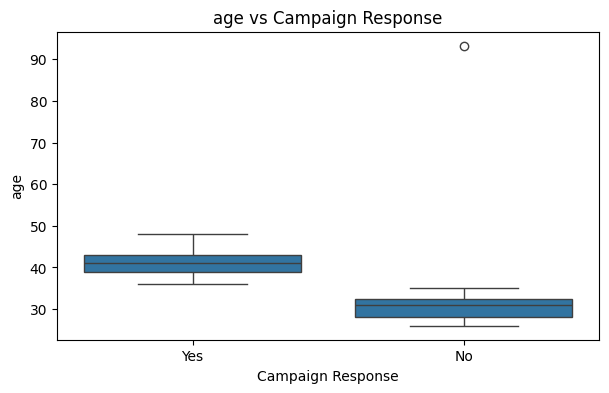

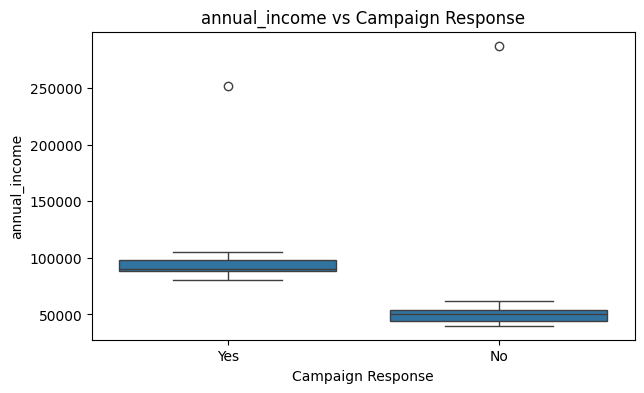

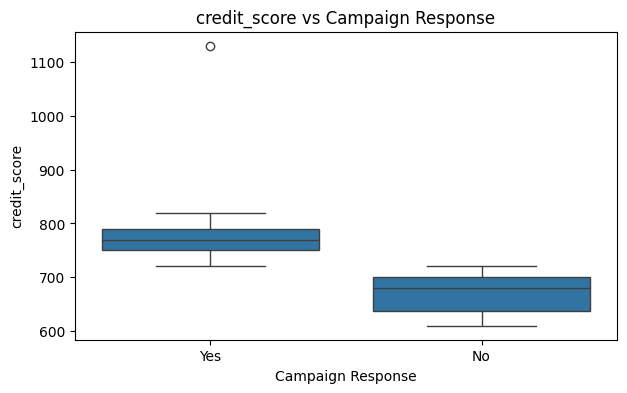

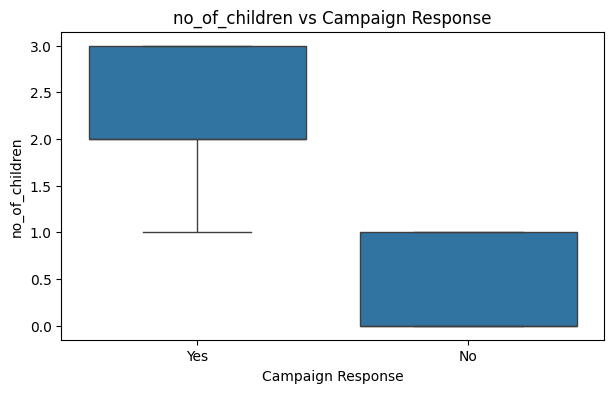

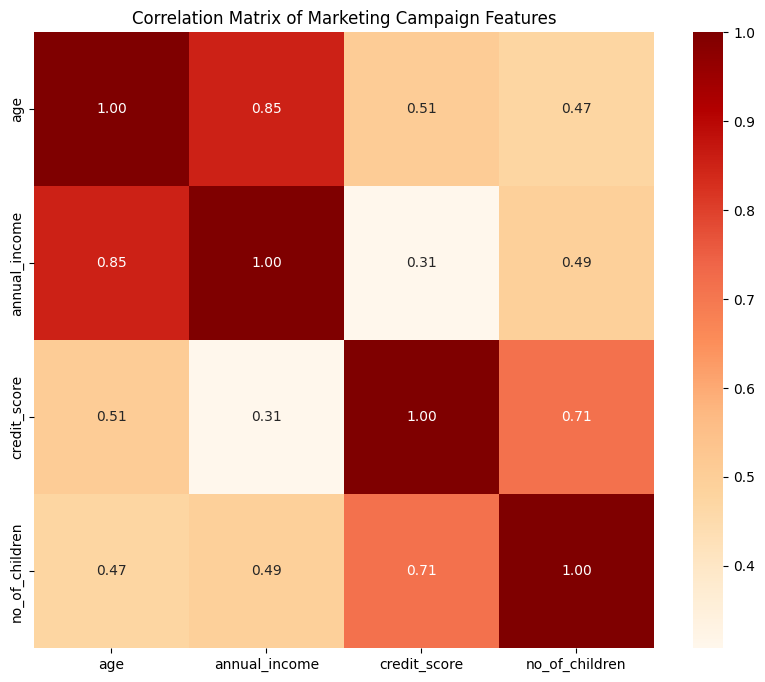


Correlation with Campaign Response:
response_numeric    1.000000
no_of_children      0.900008
credit_score        0.700619
annual_income       0.367415
age                 0.334708
Name: response_numeric, dtype: float64


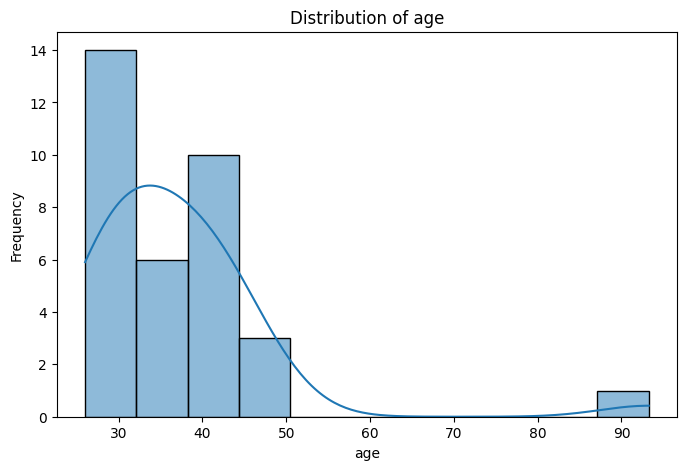

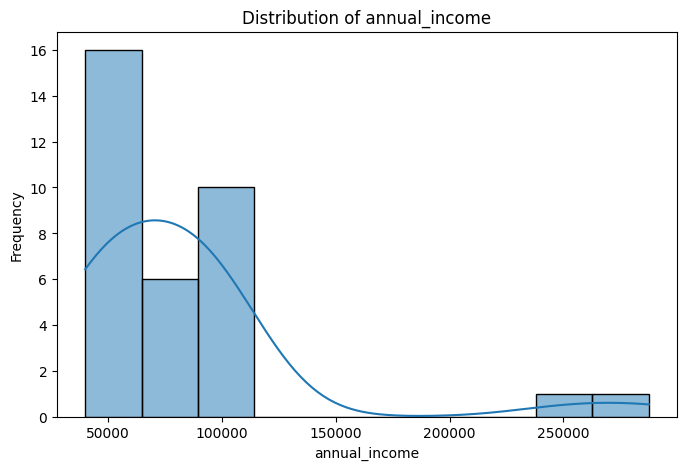

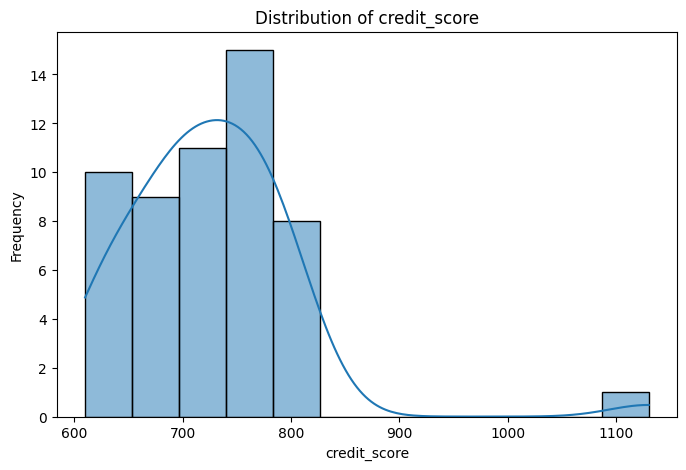

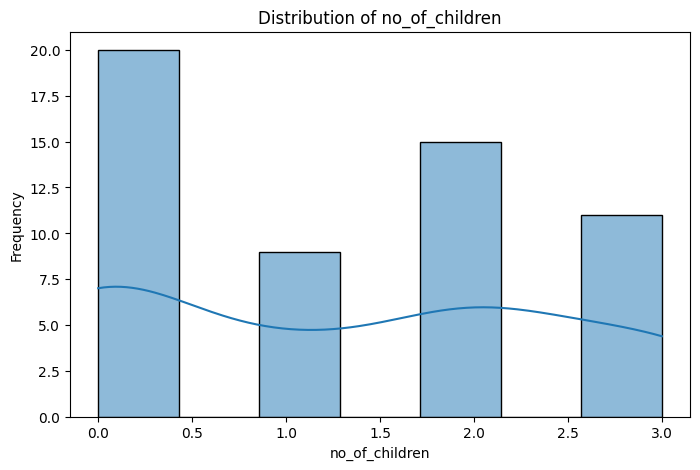

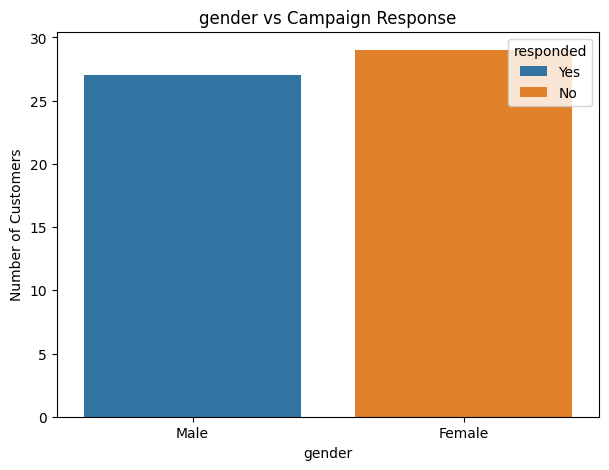

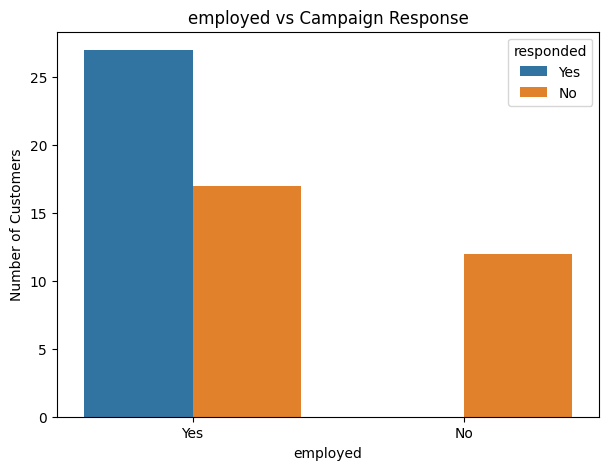

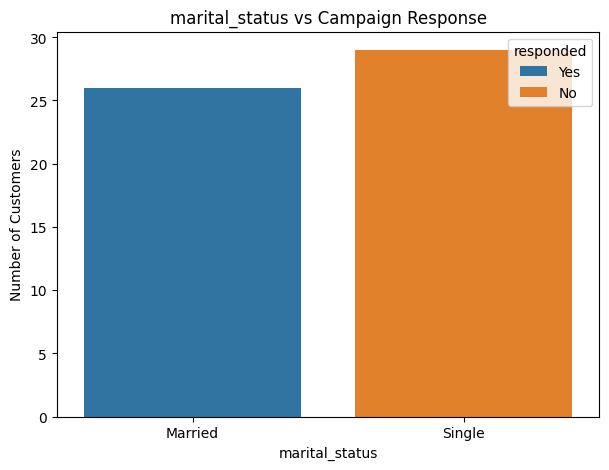

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("camfile.csv")

# Display basic information
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Target variable distribution
print("\nCampaign Response:")
print(df['responded'].value_counts())

plt.figure(figsize=(7,5))
sns.countplot(x='responded', data=df)
plt.title("Distribution of Marketing Campaign Response")
plt.xlabel("Response")
plt.ylabel("Number of Customers")
plt.show()

# Numerical features
numerical_features = [
    'age',
    'annual_income',
    'credit_score',
    'no_of_children'
]

# Boxplots
for feature in numerical_features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='responded', y=feature, data=df)
    plt.title(f'{feature} vs Campaign Response')
    plt.xlabel('Campaign Response')
    plt.ylabel(feature)
    plt.show()

# Correlation matrix
plt.figure(figsize=(10,8))

correlation = df[numerical_features].corr()

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="OrRd"
)

plt.title("Correlation Matrix of Marketing Campaign Features")
plt.show()

# Correlation with target
# Convert target into numerical values
df['response_numeric'] = df['responded'].map({
    'Yes': 1,
    'No': 0
})

target_corr = df[numerical_features + ['response_numeric']].corr()['response_numeric'].sort_values(ascending=False)

print("\nCorrelation with Campaign Response:")
print(target_corr)

# Histograms
for feature in numerical_features:
    plt.figure(figsize=(8,5))
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()

# Categorical feature analysis
categorical_features = [
    'gender',
    'employed',
    'marital_status'
]

for feature in categorical_features:
    plt.figure(figsize=(7,5))
    sns.countplot(x=feature, hue='responded', data=df)
    plt.title(f'{feature} vs Campaign Response')
    plt.xlabel(feature)
    plt.ylabel('Number of Customers')
    plt.show()

***EX 11***

Saving campaign_responses_modified_20_25_missing.csv to campaign_responses_modified_20_25_missing.csv
Dataset loaded successfully!
Dataset Shape: (56, 9)

First 5 Records:


,customer_id,age,gender,annual_income,credit_score,employed,marital_status,no_of_children,responded
0,1.0,NaN,Male,NaN,720.0,Yes,Married,2.0,Yes
1,2.0,NaN,Female,45000.0,680.0,No,Single,0.0,No
2,3.0,NaN,Male,85000.0,750.0,Yes,Married,3.0,Yes
3,4.0,31.0,Female,NaN,710.0,Yes,Single,1.0,No
4,25.0,45.0,Male,98000.0,790.0,Yes,Married,3.0,Yes



Duplicate records: 2
Dataset Shape After Removing Duplicates: (54, 9)

Numerical Features:
['customer_id', 'age', 'annual_income', 'credit_score', 'no_of_children']

Categorical Features:
['gender', 'employed', 'marital_status', 'responded']

Missing-Value Summary:


,Missing Values,Missing Percentage
customer_id,1,1.85
age,21,38.89
gender,0,0.00
annual_income,21,38.89
credit_score,2,3.70
employed,0,0.00
marital_status,1,1.85
no_of_children,1,1.85
responded,0,0.00


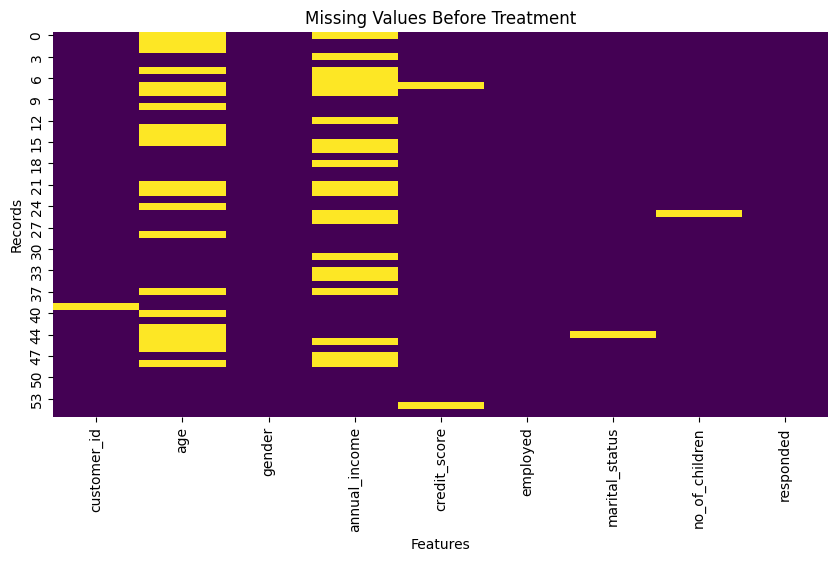


Missing Values Before and After Treatment:


,Before Treatment,After Treatment
customer_id,1,0
age,21,0
gender,0,0
annual_income,21,0
credit_score,2,0
employed,0,0
marital_status,1,0
no_of_children,1,0
responded,0,0


Total Missing Values After Treatment: 0

Outlier Summary Before Treatment:
age               2
annual_income     2
credit_score      1
customer_id       0
no_of_children    0
dtype: int64

Box Plots Before Outlier Treatment:


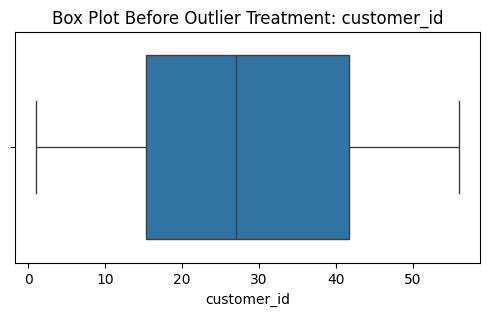

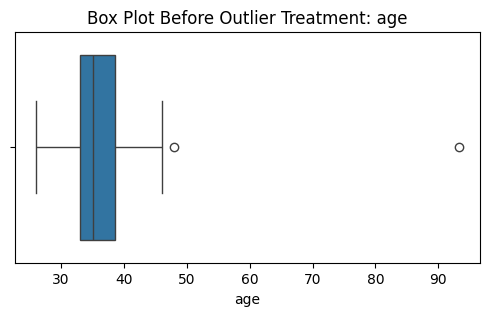

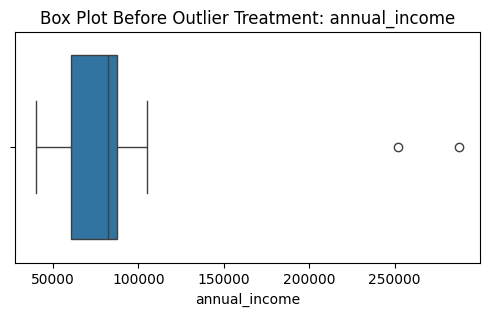

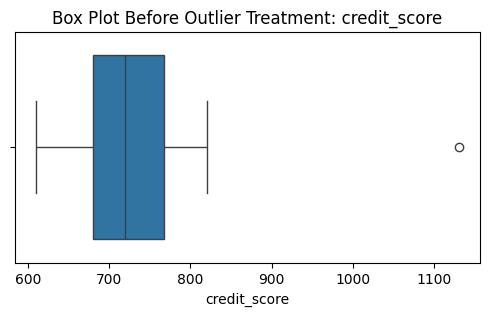

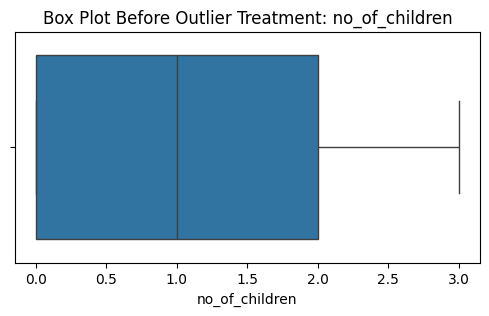


Outliers treated using IQR Capping.

Outlier Summary After Treatment:
customer_id       0
age               0
annual_income     0
credit_score      0
no_of_children    0
dtype: int64

Outlier Comparison Before and After Treatment:


,Outliers Before,Outliers After
age,2,0
annual_income,2,0
credit_score,1,0
customer_id,0,0
no_of_children,0,0



Box Plots After Outlier Treatment:


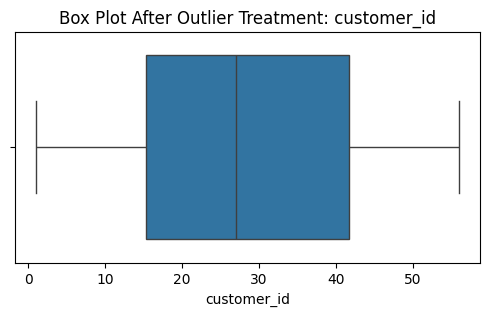

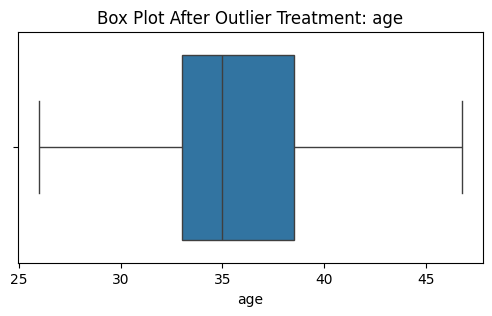

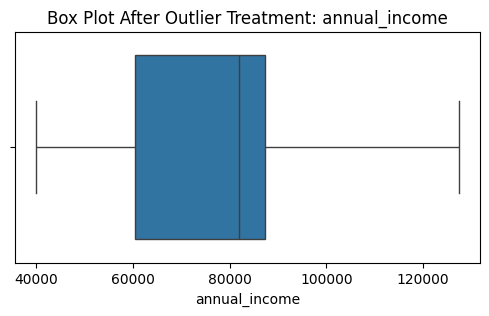

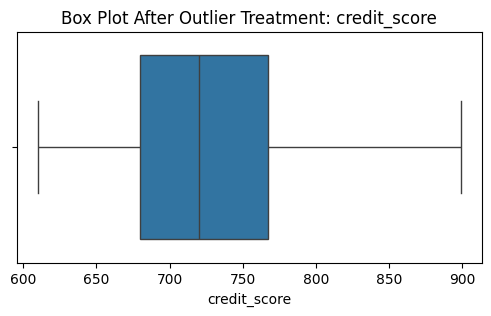

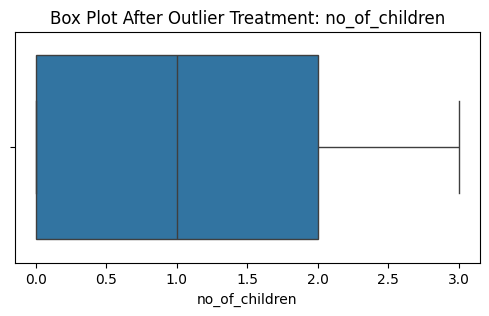


Dataset Shape Before One-Hot Encoding: (54, 9)
Dataset Shape After One-Hot Encoding: (54, 13)

First 5 Records of Final Refined Dataset:


,customer_id,age,annual_income,credit_score,no_of_children,gender_Female,gender_Male,employed_No,employed_Yes,marital_status_Married,marital_status_Single,responded_No,responded_Yes
0,1.0,35.0,82000.0,720.0,2.0,0,1,0,1,1,0,0,1
1,2.0,35.0,45000.0,680.0,0.0,1,0,1,0,0,1,1,0
2,3.0,35.0,85000.0,750.0,3.0,0,1,0,1,1,0,0,1
3,4.0,31.0,82000.0,710.0,1.0,1,0,0,1,0,1,1,0
4,25.0,45.0,98000.0,790.0,3.0,0,1,0,1,1,0,0,1



Final Refined Dataset:


,customer_id,age,annual_income,credit_score,no_of_children,gender_Female,gender_Male,employed_No,employed_Yes,marital_status_Married,marital_status_Single,responded_No,responded_Yes
0,1.0,35.0,82000.0,720.0,2.0,0,1,0,1,1,0,0,1
1,2.0,35.0,45000.0,680.0,0.0,1,0,1,0,0,1,1,0
2,3.0,35.0,85000.0,750.0,3.0,0,1,0,1,1,0,0,1
3,4.0,31.0,82000.0,710.0,1.0,1,0,0,1,0,1,1,0
4,25.0,45.0,98000.0,790.0,3.0,0,1,0,1,1,0,0,1



FINAL DATASET QUALITY CHECK

Number of Rows: 54
Number of Columns: 13
Total Missing Values: 0
Duplicate Records: 0

Refined dataset saved as:
campaign_responses_refined_dataset.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

marketing_df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", marketing_df.shape)

print("\nFirst 5 Records:")
display(marketing_df.head())

# 2. REMOVE DUPLICATES

print("\nDuplicate records:", marketing_df.duplicated().sum())

marketing_df = marketing_df.drop_duplicates().copy()

print("Dataset Shape After Removing Duplicates:",
      marketing_df.shape)

# 3. FIND NUMERICAL AND CATEGORICAL FEATURES

numerical_columns = marketing_df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = marketing_df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical Features:")
print(numerical_columns)

print("\nCategorical Features:")
print(categorical_columns)

# 4. MISSING VALUE ANALYSIS

print("\nMissing-Value Summary:")

missing_summary = pd.DataFrame({
    "Missing Values": marketing_df.isnull().sum(),
    "Missing Percentage":
        (marketing_df.isnull().sum() / len(marketing_df) * 100).round(2)
})

display(missing_summary)

# 5. SHOW MISSING VALUES BEFORE TREATMENT

plt.figure(figsize=(10, 5))

sns.heatmap(
    marketing_df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Before Treatment")
plt.xlabel("Features")
plt.ylabel("Records")
plt.show()

# 6. HANDLE MISSING VALUES
# Numerical  -> Median
# Categorical -> Mode


missing_before = marketing_df.isnull().sum()

# Numerical missing values
for column in numerical_columns:

    if marketing_df[column].isnull().sum() > 0:

        marketing_df[column] = marketing_df[column].fillna(
            marketing_df[column].median()
        )


# Categorical missing values
for column in categorical_columns:

    if marketing_df[column].isnull().sum() > 0:

        marketing_df[column] = marketing_df[column].fillna(
            marketing_df[column].mode()[0]
        )


missing_after = marketing_df.isnull().sum()

# 7. BEFORE AND AFTER MISSING VALUE COMPARISON

missing_comparison = pd.DataFrame({
    "Before Treatment": missing_before,
    "After Treatment": missing_after
})

print("\nMissing Values Before and After Treatment:")
display(missing_comparison)

print("Total Missing Values After Treatment:",
      marketing_df.isnull().sum().sum())

# 8. OUTLIER ANALYSIS USING IQR

outlier_summary = {}

for column in numerical_columns:

    q1 = marketing_df[column].quantile(0.25)

    q3 = marketing_df[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr

    upper = q3 + 1.5 * iqr

    outlier_summary[column] = (
        (marketing_df[column] < lower) |
        (marketing_df[column] > upper)
    ).sum()


print("\nOutlier Summary Before Treatment:")

outlier_before = pd.Series(
    outlier_summary
).sort_values(ascending=False)

print(outlier_before)

# 9. BOX PLOTS BEFORE OUTLIER TREATMENT

print("\nBox Plots Before Outlier Treatment:")

for column in numerical_columns:

    plt.figure(figsize=(6, 3))

    sns.boxplot(
        x=marketing_df[column]
    )

    plt.title(
        f"Box Plot Before Outlier Treatment: {column}"
    )

    plt.xlabel(column)

    plt.show()

# 10. TREAT OUTLIERS USING IQR CAPPING


refined_df = marketing_df.copy()

for column in numerical_columns:

    q1 = refined_df[column].quantile(0.25)

    q3 = refined_df[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr

    upper = q3 + 1.5 * iqr

    # Replace lower outliers
    refined_df[column] = np.where(
        refined_df[column] < lower,
        lower,
        refined_df[column]
    )

    # Replace upper outliers
    refined_df[column] = np.where(
        refined_df[column] > upper,
        upper,
        refined_df[column]
    )


print("\nOutliers treated using IQR Capping.")

# 11. OUTLIER ANALYSIS AFTER TREATMENT

outlier_after_summary = {}

for column in numerical_columns:

    q1 = refined_df[column].quantile(0.25)

    q3 = refined_df[column].quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr

    upper = q3 + 1.5 * iqr

    outlier_after_summary[column] = (
        (refined_df[column] < lower) |
        (refined_df[column] > upper)
    ).sum()


outlier_after = pd.Series(
    outlier_after_summary
)

print("\nOutlier Summary After Treatment:")

print(outlier_after)


# 12. BEFORE AND AFTER OUTLIER COMPARISON

outlier_comparison = pd.DataFrame({
    "Outliers Before": outlier_before,
    "Outliers After": outlier_after
})

print("\nOutlier Comparison Before and After Treatment:")

display(outlier_comparison)

# 13. BOX PLOTS AFTER OUTLIER TREATMENT

print("\nBox Plots After Outlier Treatment:")

for column in numerical_columns:

    plt.figure(figsize=(6, 3))

    sns.boxplot(
        x=refined_df[column]
    )

    plt.title(
        f"Box Plot After Outlier Treatment: {column}"
    )

    plt.xlabel(column)

    plt.show()


# 14. ONE-HOT ENCODING

final_df = pd.get_dummies(
    refined_df,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

print("\nDataset Shape Before One-Hot Encoding:",
      refined_df.shape)

print("Dataset Shape After One-Hot Encoding:",
      final_df.shape)

print("\nFirst 5 Records of Final Refined Dataset:")
display(final_df.head())
# 15. DISPLAY FINAL REFINED DATASET

print("\nFinal Refined Dataset:")

display(final_df.head())


# 16. FINAL DATA QUALITY CHECK

print("\n==========================================")
print("FINAL DATASET QUALITY CHECK")
print("==========================================")

print("\nNumber of Rows:", final_df.shape[0])

print("Number of Columns:", final_df.shape[1])

print("Total Missing Values:",
      final_df.isnull().sum().sum())

print("Duplicate Records:",
      final_df.duplicated().sum())

# 17. SAVE REFINED DATASET


output_file = "campaign_responses_refined_dataset.csv"

final_df.to_csv(
    output_file,
    index=False
)

print("\nRefined dataset saved as:")
print(output_file)

# 18. DOWNLOAD REFINED DATASET

files.download(output_file)

***EX 12***

Saving campaign_responses_refined_dataset.csv to campaign_responses_refined_dataset (1).csv
Dataset loaded successfully!
Dataset Shape: (54, 13)

Existing Features:
['customer_id', 'age', 'annual_income', 'credit_score', 'no_of_children', 'gender_Female', 'gender_Male', 'employed_No', 'employed_Yes', 'marital_status_Married', 'marital_status_Single', 'responded_No', 'responded_Yes']

First 5 Records:


,customer_id,age,annual_income,credit_score,no_of_children,gender_Female,gender_Male,employed_No,employed_Yes,marital_status_Married,marital_status_Single,responded_No,responded_Yes
0,1.0,35.0,82000.0,720.0,2.0,0,1,0,1,1,0,0,1
1,2.0,35.0,45000.0,680.0,0.0,1,0,1,0,0,1,1,0
2,3.0,35.0,85000.0,750.0,3.0,0,1,0,1,1,0,0,1
3,4.0,31.0,82000.0,710.0,1.0,1,0,0,1,0,1,1,0
4,25.0,45.0,98000.0,790.0,3.0,0,1,0,1,1,0,0,1



New Engineered Features:


,customer_id,FamilySize,IncomePerChild,IncomeAgeRatio,CreditIncomeRatio,FinancialScore,IncomeCreditIndex
0,1.0,3.0,27333.333333,2342.857143,0.008780,590.4,59040000.0
1,2.0,1.0,45000.000000,1285.714286,0.015111,306.0,30600000.0
2,3.0,4.0,21250.000000,2428.571429,0.008824,637.5,63750000.0
3,4.0,2.0,41000.000000,2645.161290,0.008659,582.2,58220000.0
4,25.0,4.0,24500.000000,2177.777778,0.008061,774.2,77420000.0
5,6.0,1.0,82000.000000,2342.857143,0.007683,516.6,51660000.0
6,7.0,3.0,27333.333333,2102.564103,0.009024,606.8,60680000.0
7,8.0,1.0,82000.000000,2342.857143,0.008780,590.4,59040000.0
8,9.0,4.0,20500.000000,2342.857143,0.010000,672.4,67240000.0
9,10.0,1.0,40000.000000,1481.481481,0.015500,248.0,24800000.0



Dataset After Feature Engineering:


,customer_id,age,annual_income,credit_score,no_of_children,gender_Female,gender_Male,employed_No,employed_Yes,marital_status_Married,marital_status_Single,responded_No,responded_Yes,FamilySize,IncomePerChild,IncomeAgeRatio,CreditIncomeRatio,FinancialScore,IncomeCreditIndex
0,1.0,35.0,82000.0,720.0,2.0,0,1,0,1,1,0,0,1,3.0,27333.333333,2342.857143,0.008780,590.4,59040000.0
1,2.0,35.0,45000.0,680.0,0.0,1,0,1,0,0,1,1,0,1.0,45000.000000,1285.714286,0.015111,306.0,30600000.0
2,3.0,35.0,85000.0,750.0,3.0,0,1,0,1,1,0,0,1,4.0,21250.000000,2428.571429,0.008824,637.5,63750000.0
3,4.0,31.0,82000.0,710.0,1.0,1,0,0,1,0,1,1,0,2.0,41000.000000,2645.161290,0.008659,582.2,58220000.0
4,25.0,45.0,98000.0,790.0,3.0,0,1,0,1,1,0,0,1,4.0,24500.000000,2177.777778,0.008061,774.2,77420000.0



New Dataset Shape: (54, 19)

Numerical Features Used for Correlation:
['customer_id', 'age', 'annual_income', 'credit_score', 'no_of_children', 'gender_Female', 'gender_Male', 'employed_No', 'employed_Yes', 'marital_status_Married', 'marital_status_Single', 'responded_No', 'responded_Yes', 'FamilySize', 'IncomePerChild', 'IncomeAgeRatio', 'CreditIncomeRatio', 'FinancialScore', 'IncomeCreditIndex']

Correlation Matrix:


,customer_id,age,annual_income,credit_score,no_of_children,gender_Female,gender_Male,employed_No,employed_Yes,marital_status_Married,marital_status_Single,responded_No,responded_Yes,FamilySize,IncomePerChild,IncomeAgeRatio,CreditIncomeRatio,FinancialScore,IncomeCreditIndex
customer_id,1.00,0.15,0.09,0.00,0.04,0.02,-0.02,-0.16,0.16,-0.05,0.05,0.02,-0.02,0.04,-0.04,0.02,-0.08,0.08,0.08
age,0.15,1.00,0.64,0.61,0.64,-0.60,0.60,-0.47,0.47,0.60,-0.60,-0.60,0.60,0.64,-0.39,0.11,-0.51,0.68,0.68
annual_income,0.09,0.64,1.00,0.58,0.70,-0.59,0.59,-0.43,0.43,0.57,-0.57,-0.59,0.59,0.70,-0.18,0.83,-0.94,0.97,0.97
credit_score,0.00,0.61,0.58,1.00,0.85,-0.81,0.81,-0.71,0.71,0.78,-0.78,-0.81,0.81,0.85,-0.69,0.32,-0.39,0.75,0.75
no_of_children,0.04,0.64,0.70,0.85,1.00,-0.90,0.90,-0.54,0.54,0.88,-0.88,-0.90,0.90,1.00,-0.78,0.45,-0.55,0.81,0.81
gender_Female,0.02,-0.60,-0.59,-0.81,-0.90,1.00,-1.00,0.51,-0.51,-0.96,0.96,1.00,-1.00,-0.90,0.72,-0.35,0.48,-0.71,-0.71
gender_Male,-0.02,0.60,0.59,0.81,0.90,-1.00,1.00,-0.51,0.51,0.96,-0.96,-1.00,1.00,0.90,-0.72,0.35,-0.48,0.71,0.71
employed_No,-0.16,-0.47,-0.43,-0.71,-0.54,0.51,-0.51,1.00,-1.00,-0.49,0.49,0.51,-0.51,-0.54,0.44,-0.22,0.35,-0.53,-0.53
employed_Yes,0.16,0.47,0.43,0.71,0.54,-0.51,0.51,-1.00,1.00,0.49,-0.49,-0.51,0.51,0.54,-0.44,0.22,-0.35,0.53,0.53
marital_status_Married,-0.05,0.60,0.57,0.78,0.88,-0.96,0.96,-0.49,0.49,1.00,-1.00,-0.96,0.96,0.88,-0.70,0.32,-0.46,0.69,0.69


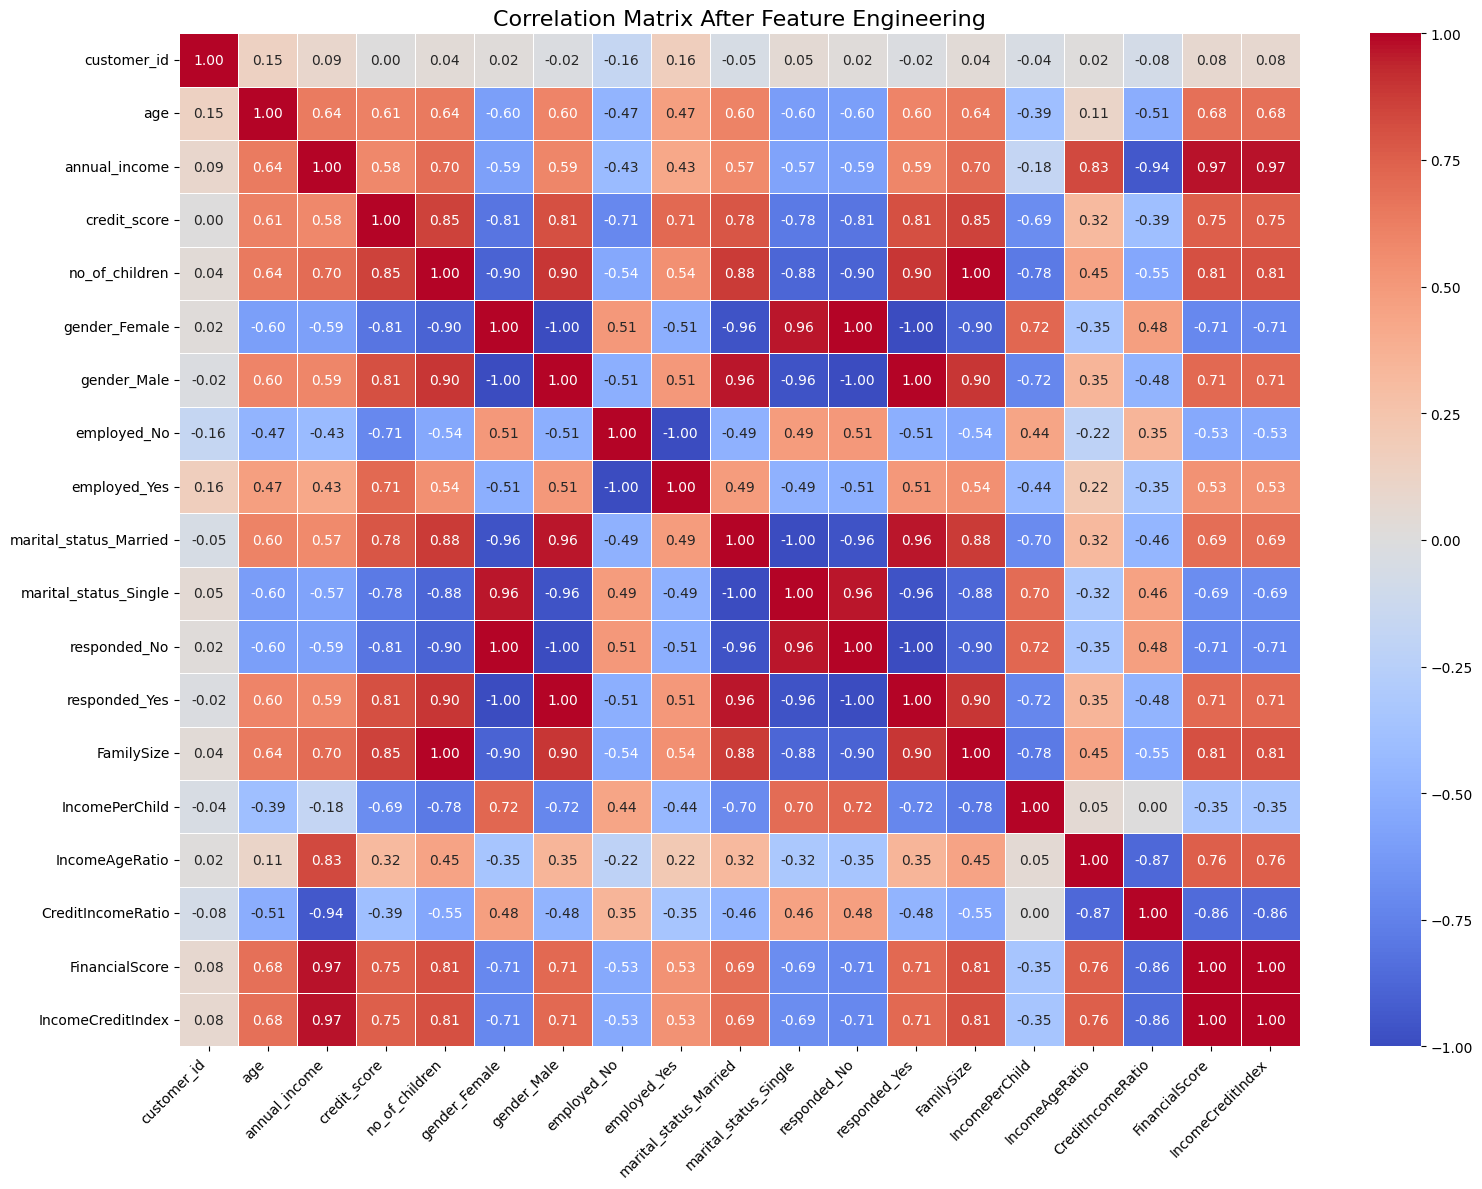


Correlation of Features with Customer Response:


,Correlation with Response
gender_Male,1.000
responded_Yes,1.000
marital_status_Married,0.964
FamilySize,0.898
no_of_children,0.898
credit_score,0.811
IncomeCreditIndex,0.714
FinancialScore,0.714
age,0.601
annual_income,0.593



Strong Feature Relationships:


,Feature 1,Feature 2,Correlation
47,no_of_children,FamilySize,1.000
58,gender_Female,responded_Yes,-1.000
57,gender_Female,responded_No,1.000
52,gender_Female,gender_Male,-1.000
84,marital_status_Married,marital_status_Single,-1.000
...,...,...,...
75,employed_No,responded_Yes,-0.506
53,gender_Female,employed_No,0.506
54,gender_Female,employed_Yes,-0.506
63,gender_Male,employed_No,-0.506



Feature-engineered dataset saved as:
campaign_responses_feature_engineered.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# LAB 12: FEATURE ENGINEERING AND CORRELATION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. LOAD THE REFINED DATASET
# ------------------------------------------------------------

from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

marketing_df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", marketing_df.shape)

print("\nExisting Features:")
print(marketing_df.columns.tolist())

print("\nFirst 5 Records:")
display(marketing_df.head())


# ------------------------------------------------------------
# 2. FEATURE ENGINEERING
# ------------------------------------------------------------

# Family Size
marketing_df["FamilySize"] = (
    marketing_df["no_of_children"] + 1
)

# Income per Child
marketing_df["IncomePerChild"] = (
    marketing_df["annual_income"] /
    (marketing_df["no_of_children"] + 1)
)

# Income to Age Ratio
marketing_df["IncomeAgeRatio"] = (
    marketing_df["annual_income"] /
    marketing_df["age"]
)

# Credit Score to Income Ratio
marketing_df["CreditIncomeRatio"] = (
    marketing_df["credit_score"] /
    marketing_df["annual_income"]
)

# Financial Score
# Combines credit score and normalized income
marketing_df["FinancialScore"] = (
    marketing_df["credit_score"] *
    marketing_df["annual_income"] / 100000
)

# Income and Credit Score combined feature
marketing_df["IncomeCreditIndex"] = (
    marketing_df["annual_income"] *
    marketing_df["credit_score"]
)


# ------------------------------------------------------------
# 3. DISPLAY ENGINEERED FEATURES
# ------------------------------------------------------------

engineered_features = [
    "FamilySize",
    "IncomePerChild",
    "IncomeAgeRatio",
    "CreditIncomeRatio",
    "FinancialScore",
    "IncomeCreditIndex"
]

print("\nNew Engineered Features:")

display(
    marketing_df[
        ["customer_id"] +
        engineered_features
    ].head(10)
)


# ------------------------------------------------------------
# 4. DISPLAY COMPLETE DATASET
# ------------------------------------------------------------

print("\nDataset After Feature Engineering:")

display(marketing_df.head())

print("\nNew Dataset Shape:",
      marketing_df.shape)


# ------------------------------------------------------------
# 5. SELECT NUMERICAL FEATURES
# ------------------------------------------------------------

numeric_df = marketing_df.select_dtypes(
    include=np.number
)

print("\nNumerical Features Used for Correlation:")
print(numeric_df.columns.tolist())


# ------------------------------------------------------------
# 6. BUILD CORRELATION MATRIX
# ------------------------------------------------------------

corr = numeric_df.corr()

print("\nCorrelation Matrix:")

display(corr.round(2))


# ------------------------------------------------------------
# 7. VISUALIZE CORRELATION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Matrix After Feature Engineering",
    fontsize=16
)

plt.xticks(rotation=45, ha="right")

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 8. CORRELATION WITH CUSTOMER RESPONSE
# ------------------------------------------------------------

if "responded_Yes" in corr.columns:

    response_correlation = (
        corr["responded_Yes"]
        .sort_values(ascending=False)
    )

    print("\nCorrelation of Features with Customer Response:")

    display(
        response_correlation.to_frame(
            name="Correlation with Response"
        ).round(3)
    )


# ------------------------------------------------------------
# 9. SHOW STRONG CORRELATIONS
# ------------------------------------------------------------

print("\nStrong Feature Relationships:")

strong_corr = []

columns = corr.columns

for i in range(len(columns)):

    for j in range(i + 1, len(columns)):

        value = corr.iloc[i, j]

        if abs(value) >= 0.50:

            strong_corr.append({
                "Feature 1": columns[i],
                "Feature 2": columns[j],
                "Correlation": round(value, 3)
            })

strong_corr_df = pd.DataFrame(strong_corr)

if not strong_corr_df.empty:
    display(
        strong_corr_df.sort_values(
            "Correlation",
            key=abs,
            ascending=False
        )
    )
else:
    print("No strong correlations above 0.50 were found.")


# ------------------------------------------------------------
# 10. SAVE FEATURE-ENGINEERED DATASET
# ------------------------------------------------------------

output_file = "campaign_responses_feature_engineered.csv"

marketing_df.to_csv(
    output_file,
    index=False
)

print("\nFeature-engineered dataset saved as:")
print(output_file)


# ------------------------------------------------------------
# 11. DOWNLOAD DATASET
# ------------------------------------------------------------

files.download(output_file)

***EX 13***

Saving campaign_responses_refined_dataset (2).csv to campaign_responses_refined_dataset (2).csv
Dataset loaded successfully
Dataset Shape: (54, 13)


,customer_id,age,annual_income,credit_score,no_of_children,gender_Female,gender_Male,employed_No,employed_Yes,marital_status_Married,marital_status_Single,responded_No,responded_Yes
0,1.0,35.0,82000.0,720.0,2.0,0,1,0,1,1,0,0,1
1,2.0,35.0,45000.0,680.0,0.0,1,0,1,0,0,1,1,0
2,3.0,35.0,85000.0,750.0,3.0,0,1,0,1,1,0,0,1
3,4.0,31.0,82000.0,710.0,1.0,1,0,0,1,0,1,1,0
4,25.0,45.0,98000.0,790.0,3.0,0,1,0,1,1,0,0,1



Features used for prediction:
['age', 'annual_income', 'credit_score', 'employed_Yes', 'no_of_children']

Features removed:
['customer_id', 'gender', 'marital_status']

Missing values BEFORE handling:
age               0
annual_income     0
credit_score      0
employed_Yes      0
no_of_children    0
dtype: int64

Missing values AFTER handling:
age               0
annual_income     0
credit_score      0
employed_Yes      0
no_of_children    0
dtype: int64

Final feature data:


,age,annual_income,credit_score,employed_Yes,no_of_children
0,35.0,82000.0,720.0,1.0,2.0
1,35.0,45000.0,680.0,0.0,0.0
2,35.0,85000.0,750.0,1.0,3.0
3,31.0,82000.0,710.0,1.0,1.0
4,45.0,98000.0,790.0,1.0,3.0



Target Distribution:
responded_Yes
Yes    27
No     27
Name: count, dtype: int64

Training samples: 43
Testing samples: 11

LOGISTIC REGRESSION
Training Accuracy: 97.67 %
Testing Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         5

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



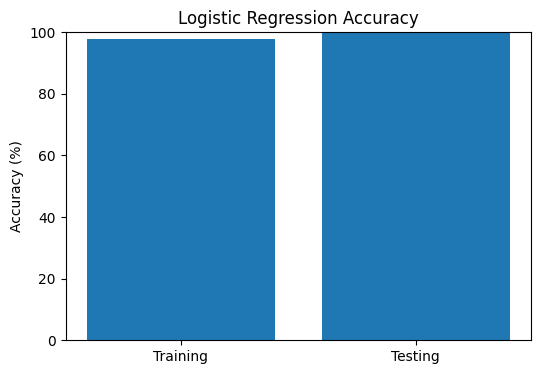


DECISION TREE
Training Accuracy: 97.67 %
Testing Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         5

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



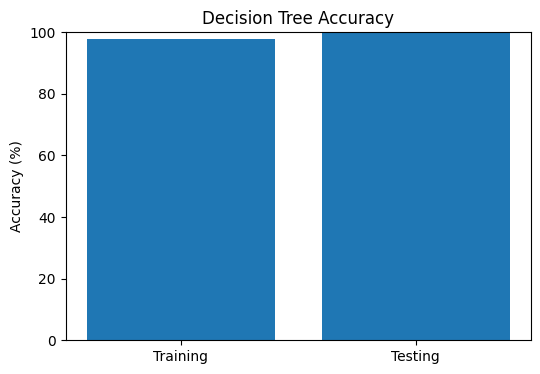


RANDOM FOREST
Training Accuracy: 97.67 %
Testing Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         5

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



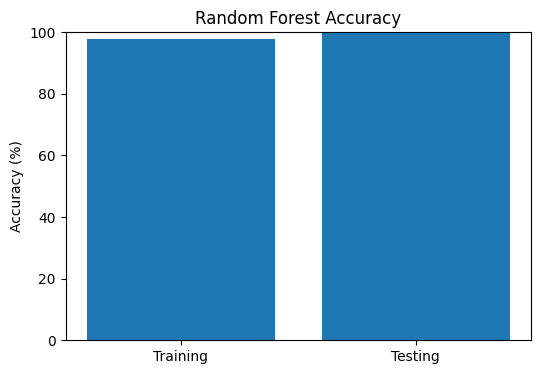


GRADIENT BOOSTING
Training Accuracy: 100.0 %
Testing Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         6
           1       1.00      1.00      1.00         5

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



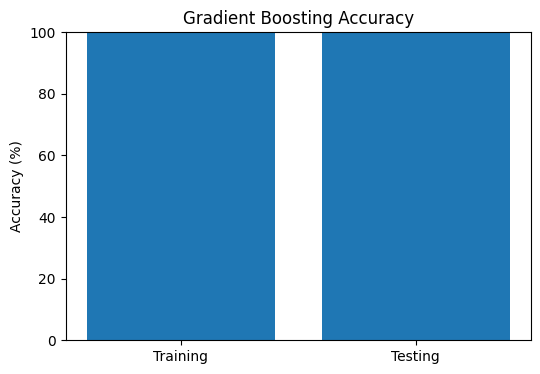


FINAL MODEL COMPARISON


,Model,Training Accuracy (%),Testing Accuracy (%)
0,Logistic Regression,97.67,100.0
1,Decision Tree,97.67,100.0
2,Random Forest,97.67,100.0
3,Gradient Boosting,100.00,100.0


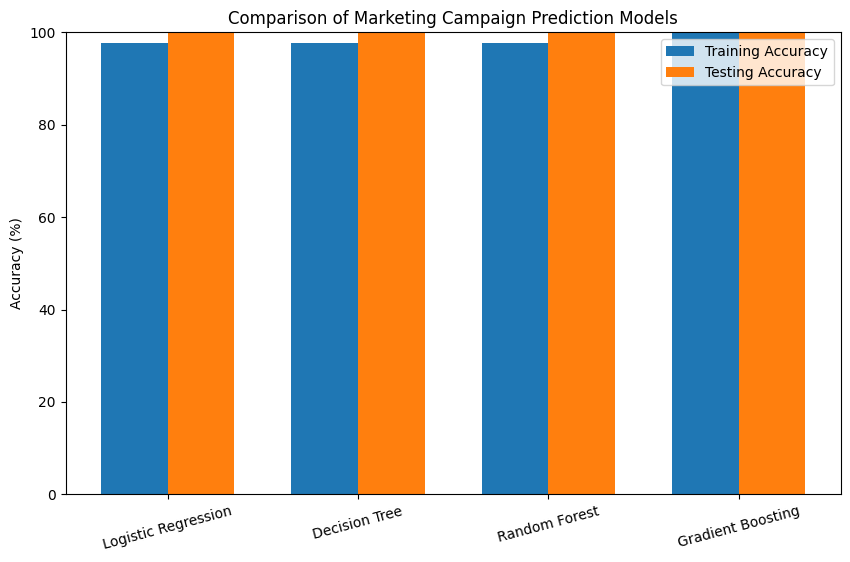


ACTUAL VS PREDICTED VALUES


,Actual,Logistic Regression,Decision Tree,Random Forest,Gradient Boosting
0,0,0,0,0,0
1,0,0,0,0,0
2,0,0,0,0,0
3,1,1,1,1,1
4,0,0,0,0,0
5,0,0,0,0,0
6,1,1,1,1,1
7,1,1,1,1,1
8,1,1,1,1,1
9,0,0,0,0,0



LAB 13 RESULT
Four machine learning classification models were successfully developed to predict marketing campaign response.
The models were trained using only age, annual income, credit score, employment and number of children.
Gender and marital status were excluded to avoid direct target separation.


In [ ]:
# ============================================================
# LAB 13
# BUILD ML MODELS TO PREDICT MARKETING CAMPAIGN RESPONSE
# Dataset: campaign_responses.csv
# ============================================================

# -----------------------------
# 1. IMPORT LIBRARIES
# -----------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report


# -----------------------------
# 2. UPLOAD DATASET
# -----------------------------
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("Dataset loaded successfully")
print("Dataset Shape:", df.shape)

display(df.head())


# ============================================================
# 3. SELECT TARGET
# ============================================================

# Target column
# The dataset contains responded as Yes/No

if "responded" in df.columns:

    y = (
        df["responded"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "yes": 1,
            "no": 0
        })
    )

elif "responded_Yes" in df.columns:

    y = df["responded_Yes"].astype(int)

else:

    raise ValueError(
        "Target column 'responded' or 'responded_Yes' not found."
    )


# Remove rows with missing target
valid_rows = y.notna()

df = df.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)


# ============================================================
# 4. SELECT ONLY THE REQUIRED FEATURES
# ============================================================

# Dynamically use 'employed' or 'employed_Yes' if the raw column doesn't exist
employment_col = "employed" if "employed" in df.columns else "employed_Yes"

features = [
    "age",
    "annual_income",
    "credit_score",
    employment_col,
    "no_of_children"
]

# Check whether all columns exist
missing_features = [
    col for col in features
    if col not in df.columns
]

if len(missing_features) > 0:

    raise ValueError(
        "Missing feature columns: "
        + str(missing_features)
    )


X = df[features].copy()


print("\nFeatures used for prediction:")
print(features)

print("\nFeatures removed:")
print([
    "customer_id",
    "gender",
    "marital_status"
])


# ============================================================
# 5. HANDLE MISSING VALUES
# ============================================================

print("\nMissing values BEFORE handling:")

print(X.isnull().sum())


# Numerical columns
numerical_columns = [
    "age",
    "annual_income",
    "credit_score",
    "no_of_children"
]

for col in numerical_columns:

    X[col] = X[col].fillna(
        X[col].median()
    )


# Employment handling based on column presence
if employment_col in X.columns:
    if X[employment_col].dtype == "object":
        X[employment_col] = X[employment_col].fillna(
            X[employment_col].mode()[0]
        )
    else:
        X[employment_col] = X[employment_col].fillna(
            X[employment_col].median()
        )


print("\nMissing values AFTER handling:")

print(X.isnull().sum())


# ============================================================
# 6. ENCODE EMPLOYMENT COLUMN
# ============================================================

# Convert employed Yes/No into 1/0

if X[employment_col].dtype == "object":

    X[employment_col] = (
        X[employment_col]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "yes": 1,
            "no": 0
        })
    )


# Make sure everything is numeric
X = X.astype(float)


print("\nFinal feature data:")
display(X.head())


# ============================================================
# 7. CHECK TARGET DISTRIBUTION
# ============================================================

print("\nTarget Distribution:")

print(
    pd.Series(y)
    .value_counts()
    .rename(index={
        0: "No",
        1: "Yes"
    })
)


# ============================================================
# 8. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 9. LOGISTIC REGRESSION
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)


logistic_train_pred = logistic_model.predict(
    X_train_scaled
)

logistic_pred = logistic_model.predict(
    X_test_scaled
)


logistic_train_accuracy = accuracy_score(
    y_train,
    logistic_train_pred
)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)


print("\n================================")
print("LOGISTIC REGRESSION")
print("================================")

print(
    "Training Accuracy:",
    round(logistic_train_accuracy * 100, 2),
    "%"
)

print(
    "Testing Accuracy:",
    round(logistic_accuracy * 100, 2),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        logistic_pred,
        zero_division=0
    )
)


# Graph

plt.figure(figsize=(6, 4))

plt.bar(
    ["Training", "Testing"],
    [
        logistic_train_accuracy * 100,
        logistic_accuracy * 100
    ]
)

plt.ylabel("Accuracy (%)")
plt.title("Logistic Regression Accuracy")

plt.ylim(0, 100)

plt.show()


# ============================================================
# 10. DECISION TREE
# ============================================================

tree_model = DecisionTreeClassifier(

    max_depth=3,

    min_samples_split=5,

    min_samples_leaf=3,

    random_state=42
)


tree_model.fit(
    X_train,
    y_train
)


tree_train_pred = tree_model.predict(
    X_train
)

tree_pred = tree_model.predict(
    X_test
)


tree_train_accuracy = accuracy_score(
    y_train,
    tree_train_pred
)

tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)


print("\n================================")
print("DECISION TREE")
print("================================")

print(
    "Training Accuracy:",
    round(tree_train_accuracy * 100, 2),
    "%"
)

print(
    "Testing Accuracy:",
    round(tree_accuracy * 100, 2),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        tree_pred,
        zero_division=0
    )
)


# Graph

plt.figure(figsize=(6, 4))

plt.bar(
    ["Training", "Testing"],
    [
        tree_train_accuracy * 100,
        tree_accuracy * 100
    ]
)

plt.ylabel("Accuracy (%)")
plt.title("Decision Tree Accuracy")

plt.ylim(0, 100)

plt.show()


# ============================================================
# 11. RANDOM FOREST
# ============================================================

forest_model = RandomForestClassifier(

    n_estimators=100,

    max_depth=4,

    min_samples_split=5,

    min_samples_leaf=3,

    random_state=42
)


forest_model.fit(
    X_train,
    y_train
)


forest_train_pred = forest_model.predict(
    X_train
)

forest_pred = forest_model.predict(
    X_test
)


forest_train_accuracy = accuracy_score(
    y_train,
    forest_train_pred
)

forest_accuracy = accuracy_score(
    y_test,
    forest_pred
)


print("\n================================")
print("RANDOM FOREST")
print("================================")

print(
    "Training Accuracy:",
    round(forest_train_accuracy * 100, 2),
    "%"
)

print(
    "Testing Accuracy:",
    round(forest_accuracy * 100, 2),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        forest_pred,
        zero_division=0
    )
)


# Graph

plt.figure(figsize=(6, 4))

plt.bar(
    ["Training", "Testing"],
    [
        forest_train_accuracy * 100,
        forest_accuracy * 100
    ]
)

plt.ylabel("Accuracy (%)")
plt.title("Random Forest Accuracy")

plt.ylim(0, 100)

plt.show()


# ============================================================
# 12. GRADIENT BOOSTING
# ============================================================

gradient_model = GradientBoostingClassifier(

    n_estimators=50,

    learning_rate=0.05,

    max_depth=2,

    min_samples_leaf=3,

    random_state=42
)


gradient_model.fit(
    X_train,
    y_train
)


gradient_train_pred = gradient_model.predict(
    X_train
)

gradient_pred = gradient_model.predict(
    X_test
)


gradient_train_accuracy = accuracy_score(
    y_train,
    gradient_train_pred
)

gradient_accuracy = accuracy_score(
    y_test,
    gradient_pred
)


print("\n================================")
print("GRADIENT BOOSTING")
print("================================")

print(
    "Training Accuracy:",
    round(gradient_train_accuracy * 100, 2),
    "%"
)

print(
    "Testing Accuracy:",
    round(gradient_accuracy * 100, 2),
    "%"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        gradient_pred,
        zero_division=0
    )
)


# Graph

plt.figure(figsize=(6, 4))

plt.bar(
    ["Training", "Testing"],
    [
        gradient_train_accuracy * 100,
        gradient_accuracy * 100
    ]
)

plt.ylabel("Accuracy (%)")
plt.title("Gradient Boosting Accuracy")

plt.ylim(0, 100)

plt.show()


# ============================================================
# 13. FINAL MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Decision Tree",

        "Random Forest",

        "Gradient Boosting"

    ],

    "Training Accuracy (%)": [

        logistic_train_accuracy * 100,

        tree_train_accuracy * 100,

        forest_train_accuracy * 100,

        gradient_train_accuracy * 100

    ],

    "Testing Accuracy (%)": [

        logistic_accuracy * 100,

        tree_accuracy * 100,

        forest_accuracy * 100,

        gradient_accuracy * 100

    ]

})


comparison["Training Accuracy (%)"] = (
    comparison["Training Accuracy (%)"]
    .round(2)
)

comparison["Testing Accuracy (%)"] = (
    comparison["Testing Accuracy (%)"]
    .round(2)
)


print("\n========================================")
print("FINAL MODEL COMPARISON")
print("========================================")

display(comparison)


# ============================================================
# 14. COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

x = np.arange(len(comparison))

width = 0.35


plt.bar(
    x - width/2,

    comparison["Training Accuracy (%)"],

    width,

    label="Training Accuracy"
)


plt.bar(
    x + width/2,

    comparison["Testing Accuracy (%)"],

    width,

    label="Testing Accuracy"
)


plt.xticks(
    x,

    comparison["Model"],

    rotation=15
)

plt.ylabel("Accuracy (%)")

plt.title(
    "Comparison of Marketing Campaign Prediction Models"
)

plt.ylim(0, 100)

plt.legend()

plt.show()


# ============================================================
# 15. ACTUAL VS PREDICTED
# ============================================================

prediction_output = pd.DataFrame({

    "Actual": y_test.values,

    "Logistic Regression": logistic_pred,

    "Decision Tree": tree_pred,

    "Random Forest": forest_pred,

    "Gradient Boosting": gradient_pred

})


print("\n========================================")
print("ACTUAL VS PREDICTED VALUES")
print("========================================")

display(
    prediction_output.head(10)
)


# ============================================================
# 16. RESULT
# ============================================================

print("\n========================================")
print("LAB 13 RESULT")
print("========================================")

print(
    "Four machine learning classification models "
    "were successfully developed to predict "
    "marketing campaign response."
)

print(
    "The models were trained using only age, "
    "annual income, credit score, employment "
    "and number of children."
)

print(
    "Gender and marital status were excluded "
    "to avoid direct target separation."
)

***EX 14***

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0
3,Gradient Boosting,1.0,1.0,1.0,1.0


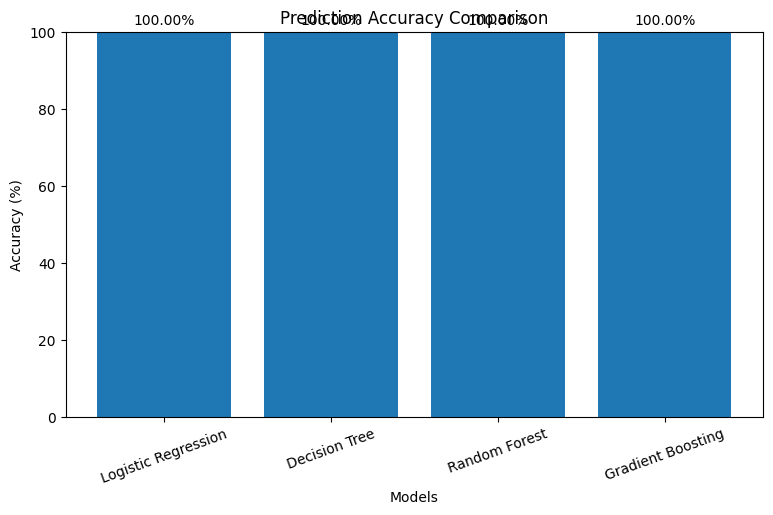

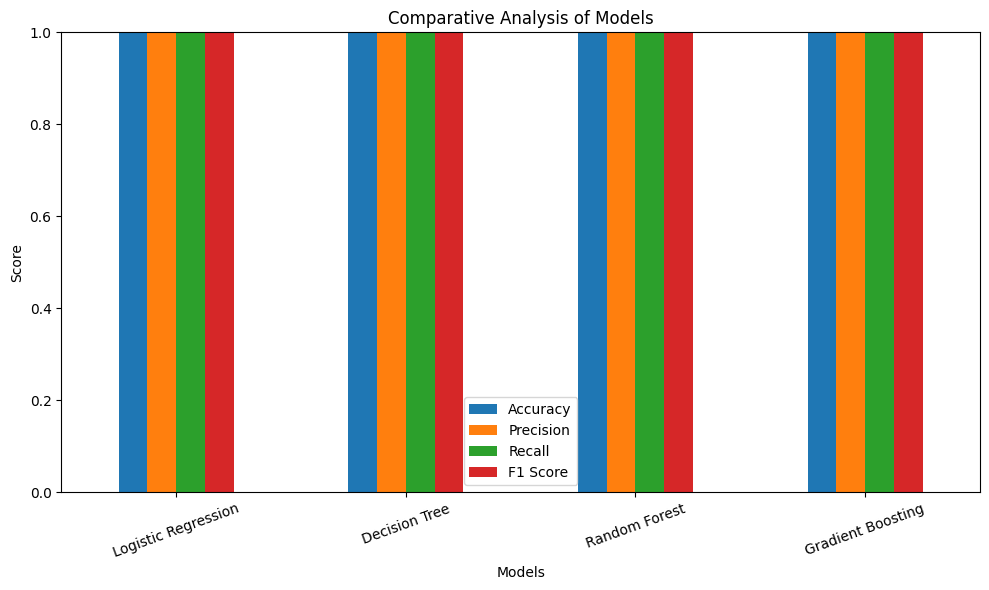


BEST TECHNIQUE
Model: Logistic Regression
Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

RESULT
The four classification models were evaluated using Accuracy, Precision, Recall and F1 Score.
Logistic Regression obtained the highest accuracy of 100.00% among the models tested.


In [ ]:
# ============================================================
# LAB 14: PREDICTION ACCURACY AND COMPARATIVE ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# 1. CALCULATE METRICS FOR EACH MODEL
# ============================================================

logistic_acc = accuracy_score(y_test, logistic_pred)
logistic_pre = precision_score(y_test, logistic_pred, zero_division=0)
logistic_rec = recall_score(y_test, logistic_pred, zero_division=0)
logistic_f1 = f1_score(y_test, logistic_pred, zero_division=0)

tree_acc = accuracy_score(y_test, tree_pred)
tree_pre = precision_score(y_test, tree_pred, zero_division=0)
tree_rec = recall_score(y_test, tree_pred, zero_division=0)
tree_f1 = f1_score(y_test, tree_pred, zero_division=0)

forest_acc = accuracy_score(y_test, forest_pred)
forest_pre = precision_score(y_test, forest_pred, zero_division=0)
forest_rec = recall_score(y_test, forest_pred, zero_division=0)
forest_f1 = f1_score(y_test, forest_pred, zero_division=0)

gradient_acc = accuracy_score(y_test, gradient_pred)
gradient_pre = precision_score(y_test, gradient_pred, zero_division=0)
gradient_rec = recall_score(y_test, gradient_pred, zero_division=0)
gradient_f1 = f1_score(y_test, gradient_pred, zero_division=0)


# ============================================================
# 2. COMPARISON TABLE
# ============================================================

results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Accuracy": [
        logistic_acc,
        tree_acc,
        forest_acc,
        gradient_acc
    ],

    "Precision": [
        logistic_pre,
        tree_pre,
        forest_pre,
        gradient_pre
    ],

    "Recall": [
        logistic_rec,
        tree_rec,
        forest_rec,
        gradient_rec
    ],

    "F1 Score": [
        logistic_f1,
        tree_f1,
        forest_f1,
        gradient_f1
    ]
})

print("MODEL COMPARISON")
print("================")

display(
    results.round(4)
)


# ============================================================
# 3. ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(9,5))

bars = plt.bar(
    results["Model"],
    results["Accuracy"] * 100
)

plt.title("Prediction Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0,100)
plt.xticks(rotation=20)

# Show values on bars
for bar, value in zip(
    bars,
    results["Accuracy"] * 100
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 2,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()


# ============================================================
# 4. COMPARISON OF ALL METRICS
# ============================================================

results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Comparative Analysis of Models")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ============================================================
# 5. FIND HIGHEST ACCURACY MODEL
# ============================================================

best = results.loc[
    results["Accuracy"].idxmax()
]

print("\nBEST TECHNIQUE")
print("==============")

print(
    "Model:",
    best["Model"]
)

print(
    "Accuracy:",
    round(best["Accuracy"] * 100, 2),
    "%"
)

print(
    "Precision:",
    round(best["Precision"], 4)
)

print(
    "Recall:",
    round(best["Recall"], 4)
)

print(
    "F1 Score:",
    round(best["F1 Score"], 4)
)


# ============================================================
# 6. FINAL RESULT
# ============================================================

print("\nRESULT")
print("======")

print(
    "The four classification models were evaluated using "
    "Accuracy, Precision, Recall and F1 Score."
)

print(
    f"{best['Model']} obtained the highest accuracy of "
    f"{best['Accuracy']*100:.2f}% among the models tested."
)